<h2 style="color:rgb(0,120,170)">Scenario 1: Full runtime</h2>

**Question:** how long does each planner take to answer one query *from scratch*?

**Setup:** graph is reconstructed from scratch for each query


The maps are the 7 batches from `maps/maps.ipynb` (10 maps each, 10 × 10, start (0, 0), goal (10, 10)), loaded from `maps/maps_batches.json`. Run `maps/maps.ipynb` first if the file doesn't exist.

| column | batch |
|---|---|
| batch_1 | different amount of obstacles (2–7, convex) |
| batch_2 | convex/concave obstacles |
| batch_3 | no obstacles |
| batch_4 | obstacles make no impact (straight line free) |
| batch_5 | few obstacles (2) |
| batch_6 | many obstacles (7) |
| batch_7 | random placement |

In [1]:
from utils.compare_tables_util import show_benchmark_tables
from utils.path_planning_utils import benchmark_batches
from utils.plot_utils import plot_algorithm_batch_means

In [2]:
from utils.maps_generation_utils import END, START, load_batches

obstacle_batches = load_batches("maps/maps_batches.json")
start, end = START, END
print(len(obstacle_batches), "batches,", [len(b) for b in obstacle_batches], "maps")

7 batches, [10, 10, 10, 10, 10, 10, 10] maps


### Settings

In [ ]:
RUNTIME_RUNS = 10
RRT_KWARGS = {"iterations": 2000}
PRM_KWARGS = {"n_samples": 150, "k": 8}

### Run the benchmark
This takes a few minutes: 7 batches × 10 maps × 3 planners × `RUNTIME_RUNS` runs.

In [4]:
scenario1_tables = benchmark_batches(
    obstacle_batches,
    start,
    end,
    rrt_kwargs=RRT_KWARGS,
    prm_kwargs=PRM_KWARGS,
    include_algorithm_setup=True,
    runtime_runs=RUNTIME_RUNS,
)

### Results per map
Runtime in seconds. Rows are maps, columns are batches.

In [5]:
show_benchmark_tables("Scenario 1", scenario1_tables)

### Scenario 1: VG

| map | batch_1 | batch_2 | batch_3 | batch_4 | batch_5 | batch_6 | batch_7 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| map_1 | 0.010996 | 0.022552 | 0.000033 | 0.001742 | 0.000665 | 0.008234 | 0.007880 |
| map_2 | 0.004972 | 0.015248 | 0.000030 | 0.003475 | 0.000552 | 0.006755 | 0.001445 |
| map_3 | 0.003567 | 0.012694 | 0.000031 | 0.003268 | 0.000559 | 0.007725 | 0.002969 |
| map_4 | 0.001590 | 0.006578 | 0.000039 | 0.004329 | 0.001016 | 0.009694 | 0.001207 |
| map_5 | 0.001012 | 0.006768 | 0.000032 | 0.006735 | 0.000547 | 0.007773 | 0.007286 |
| map_6 | 0.001866 | 0.018877 | 0.000032 | 0.000883 | 0.000853 | 0.006853 | 0.002662 |
| map_7 | 0.002339 | 0.002307 | 0.000032 | 0.001422 | 0.000713 | 0.007574 | 0.000847 |
| map_8 | 0.000685 | 0.010697 | 0.000031 | 0.002166 | 0.000652 | 0.008031 | 0.002479 |
| map_9 | 0.005469 | 0.003725 | 0.000032 | 0.006392 | 0.000680 | 0.006266 | 0.000968 |
| map_10 | 0.006150 | 0.011800 | 0.000036 | 0.000493 | 0.000422 | 0.007342 | 0.000474 |

### Scenario 1: VG summary

| batch | success_rate | median | mean | min | max | valid |
| --- | --- | --- | --- | --- | --- | --- |
| batch_1 | 100.0% | 0.002953 | 0.003864 | 0.000685 | 0.010996 | 10/10 |
| batch_2 | 100.0% | 0.011249 | 0.011125 | 0.002307 | 0.022552 | 10/10 |
| batch_3 | 100.0% | 0.000032 | 0.000033 | 0.000030 | 0.000039 | 10/10 |
| batch_4 | 100.0% | 0.002717 | 0.003091 | 0.000493 | 0.006735 | 10/10 |
| batch_5 | 100.0% | 0.000658 | 0.000666 | 0.000422 | 0.001016 | 10/10 |
| batch_6 | 100.0% | 0.007649 | 0.007625 | 0.006266 | 0.009694 | 10/10 |
| batch_7 | 100.0% | 0.001962 | 0.002822 | 0.000474 | 0.007880 | 10/10 |

Overall:
- success_rate: 100.0%
- median: 0.002323
- mean: 0.004175
- min: 0.000030
- max: 0.022552
- valid: 70/70

### Scenario 1: RRT_star

| map | batch_1 | batch_2 | batch_3 | batch_4 | batch_5 | batch_6 | batch_7 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| map_1 | 0.012205 | 0.013287 | 0.005137 | 0.006373 | 0.009828 | 0.016208 | 0.008393 |
| map_2 | 0.007648 | 0.017592 | 0.005514 | 0.007211 | 0.007231 | 0.011333 | 0.011573 |
| map_3 | 0.010081 | 0.011698 | 0.005401 | 0.008799 | 0.007346 | 0.009561 | 0.005989 |
| map_4 | 0.007943 | 0.016785 | 0.005554 | 0.006832 | 0.007101 | 0.010570 | 0.007258 |
| map_5 | 0.006844 | 0.015611 | 0.005811 | 0.006475 | 0.006396 | 0.033572 | 0.012537 |
| map_6 | 0.010818 | 0.010571 | 0.005675 | 0.007799 | 0.005683 | 0.020602 | 0.007439 |
| map_7 | 0.007322 | 0.009121 | 0.005490 | 0.006898 | 0.005707 | 0.009600 | 0.006115 |
| map_8 | 0.007668 | 0.032827 | 0.005135 | 0.006560 | 0.010519 | 0.007311 | 0.011291 |
| map_9 | 0.021565 | 0.010812 | 0.005455 | 0.007989 | 0.007653 | 0.007848 | 0.006715 |
| map_10 | 0.009085 | 0.007069 | 0.006261 | 0.005651 | 0.007456 | 0.031209 | 0.010704 |

### Scenario 1: RRT_star summary

| batch | success_rate | median | mean | min | max | valid |
| --- | --- | --- | --- | --- | --- | --- |
| batch_1 | 100.0% | 0.008514 | 0.010118 | 0.006844 | 0.021565 | 10/10 |
| batch_2 | 100.0% | 0.012492 | 0.014537 | 0.007069 | 0.032827 | 10/10 |
| batch_3 | 100.0% | 0.005502 | 0.005543 | 0.005135 | 0.006261 | 10/10 |
| batch_4 | 100.0% | 0.006865 | 0.007059 | 0.005651 | 0.008799 | 10/10 |
| batch_5 | 100.0% | 0.007289 | 0.007492 | 0.005683 | 0.010519 | 10/10 |
| batch_6 | 100.0% | 0.010952 | 0.015782 | 0.007311 | 0.033572 | 10/10 |
| batch_7 | 100.0% | 0.007916 | 0.008801 | 0.005989 | 0.012537 | 10/10 |

Overall:
- success_rate: 100.0%
- median: 0.007661
- mean: 0.009905
- min: 0.005135
- max: 0.033572
- valid: 70/70

### Scenario 1: PRM

| map | batch_1 | batch_2 | batch_3 | batch_4 | batch_5 | batch_6 | batch_7 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| map_1 | 0.019793 | 0.019468 | 0.008543 | 0.012555 | 0.010884 | 0.019654 | 0.019671 |
| map_2 | 0.017880 | 0.017480 | 0.006691 | 0.016039 | 0.010655 | 0.019313 | 0.012104 |
| map_3 | 0.017655 | 0.015977 | 0.006543 | 0.015885 | 0.010772 | 0.019429 | 0.014357 |
| map_4 | 0.012691 | 0.014388 | 0.006749 | 0.016394 | 0.010903 | 0.019743 | 0.012464 |
| map_5 | 0.012659 | 0.014487 | 0.006636 | 0.019807 | 0.013230 | NaN | 0.019887 |
| map_6 | 0.012172 | 0.019314 | 0.006593 | 0.012489 | 0.010295 | NaN | 0.013745 |
| map_7 | 0.014005 | 0.012171 | 0.006625 | 0.012329 | 0.010334 | 0.018812 | 0.010267 |
| map_8 | 0.010604 | NaN | 0.006693 | 0.012179 | 0.010504 | 0.019070 | 0.014149 |
| map_9 | 0.017955 | 0.012555 | 0.006595 | 0.019140 | 0.010506 | 0.019126 | 0.010324 |
| map_10 | 0.019268 | 0.015704 | 0.006475 | 0.010804 | 0.010436 | NaN | 0.010735 |

### Scenario 1: PRM summary

| batch | success_rate | median | mean | min | max | valid |
| --- | --- | --- | --- | --- | --- | --- |
| batch_1 | 100.0% | 0.015830 | 0.015468 | 0.010604 | 0.019793 | 10/10 |
| batch_2 | 90.0% | 0.015704 | 0.015727 | 0.012171 | 0.019468 | 9/10 |
| batch_3 | 100.0% | 0.006630 | 0.006814 | 0.006475 | 0.008543 | 10/10 |
| batch_4 | 100.0% | 0.014220 | 0.014762 | 0.010804 | 0.019807 | 10/10 |
| batch_5 | 100.0% | 0.010581 | 0.010852 | 0.010295 | 0.013230 | 10/10 |
| batch_6 | 70.0% | 0.019313 | 0.019307 | 0.018812 | 0.019743 | 7/10 |
| batch_7 | 100.0% | 0.013104 | 0.013770 | 0.010267 | 0.019887 | 10/10 |

Overall:
- success_rate: 94.3%
- median: 0.012607
- mean: 0.013536
- min: 0.006475
- max: 0.019887
- valid: 66/70

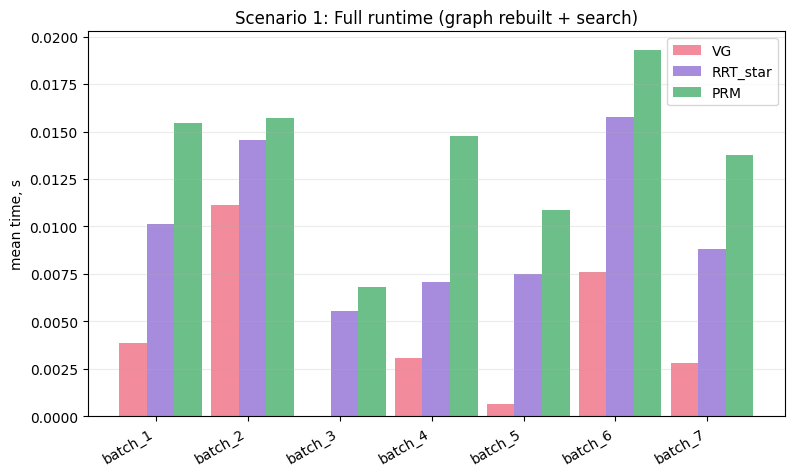

In [6]:
plot_algorithm_batch_means(
    scenario1_tables,
    title="Scenario 1: Full runtime (graph rebuilt + search)",
    ylabel="mean time, s",
);

**Result:** Comparable overall performance across the methods, however, **VG** performs better because $n$ is way smaller than minimal $N$ needed to navigate through obstacles.